In [1]:
# 13.4 파이썬 실습
# 13.4.1 가설검정의 구현
# 양측검정, 좌측검정, 우측검정의 유의수준을 0.05, 0.10, 0.01로 할 경우 기각역
#
import pandas as pd
from scipy.stats import norm

# 유의수준 설정
alpha_levels = [0.05, 0.10, 0.01]

# 검정 유형에 따른 임곗값 계산
results = []

for alpha in alpha_levels:
    two_tailed_lower = norm.ppf(alpha / 2)
    two_tailed_upper = norm.ppf(1 - alpha / 2)
    left_tailed = norm.ppf(alpha)
    right_tailed = norm.ppf(1 - alpha)

    # 결과 저장
    results.append({
        "Test Type": "Two-tailed",
        "Alpha": alpha,
        "Critical Value (Lower)": f"{two_tailed_lower:.4f}",
        "Critical Value (Upper)": f"{two_tailed_upper:.4f}"
    })
    results.append({
        "Test Type": "Left-tailed",
        "Alpha": alpha,
        "Critical Value": f"{left_tailed:.4f}",
        "Critical Value (Upper)": "N/A"
    })
    results.append({
        "Test Type": "Right-tailed",
        "Alpha": alpha,
        "Critical Value": f"{right_tailed:.4f}",
        "Critical Value (Upper)": "N/A"
    })

# 결과를 데이터프레임으로 변환
df_results = pd.DataFrame(results)

# 결과 출력
df_results


,Test Type,Alpha,Critical Value (Lower),Critical Value (Upper),Critical Value
0,Two-tailed,0.05,-1.9600,1.9600,NaN
1,Left-tailed,0.05,NaN,N/A,-1.6449
2,Right-tailed,0.05,NaN,N/A,1.6449
3,Two-tailed,0.10,-1.6449,1.6449,NaN
4,Left-tailed,0.10,NaN,N/A,-1.2816
5,Right-tailed,0.10,NaN,N/A,1.2816
6,Two-tailed,0.01,-2.5758,2.5758,NaN
7,Left-tailed,0.01,NaN,N/A,-2.3263
8,Right-tailed,0.01,NaN,N/A,2.3263


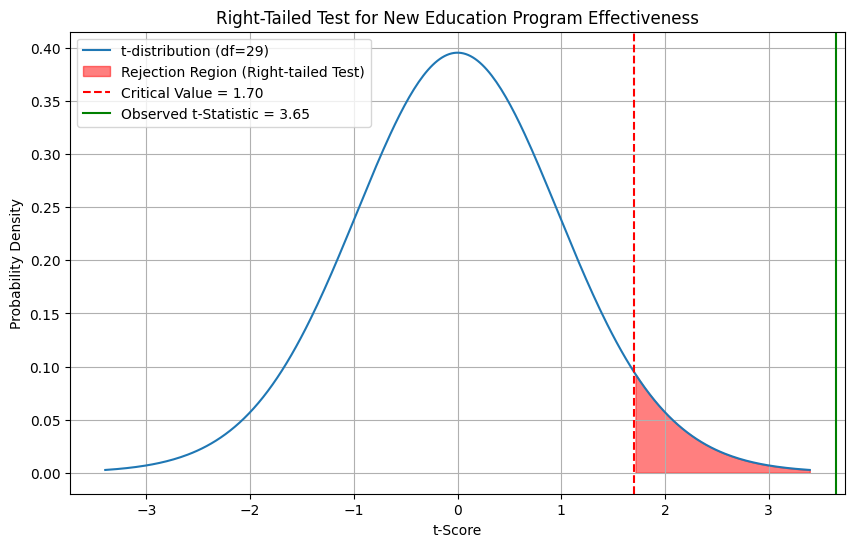

(np.float64(3.6514837167011076),
 np.float64(1.6991270265334972),
 np.float64(0.0005106476037688434))

In [2]:
# 13.4 파이썬 실습
# 13.4.2 실제 데이터 세트를 이용한 가설검정
# 실제 데이터를 활용한 가설검정
#
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import t

# 교육 프로그램 성적 데이터 설정
n = 30
sample_mean = 2  # 평균 성적 향상
sample_std = 3  # 표본 표준편차
mu_0 = 0  # 기존 프로그램 대비 성적 향상 차이 없음을 가정

# 검정 통계량 계산
t_statistic = (sample_mean - mu_0) / (sample_std / np.sqrt(n))

# 유의 수준과 임계값
alpha = 0.05  # 95% 신뢰 수준
df = n - 1
t_critical_right = t.ppf(1 - alpha, df)  # 우측검정의 t-임계값

# p-값 계산
p_value_right = 1 - t.cdf(t_statistic, df)

# t-분포 그래프
t_range = np.linspace(t.ppf(0.001, df), t.ppf(0.999, df), 300)
t_pdf = t.pdf(t_range, df)

plt.figure(figsize=(10, 6))
plt.plot(t_range, t_pdf, label='t-distribution (df=29)')
plt.fill_between(t_range, t_pdf, where=t_range >= t_critical_right, color='red', alpha=0.5, label='Rejection Region (Right-tailed Test)')
plt.axvline(x=t_critical_right, color='red', linestyle='--', label=f'Critical Value = {t_critical_right:.2f}')
plt.axvline(x=t_statistic, color='green', linestyle='-', label=f'Observed t-Statistic = {t_statistic:.2f}')
plt.title('Right-Tailed Test for New Education Program Effectiveness')
plt.xlabel('t-Score')
plt.ylabel('Probability Density')
plt.legend()
plt.grid(True)
plt.show()

t_statistic, t_critical_right, p_value_right


Sample Proportion: 0.45
z-score: 3.23
z-critical (for alpha = 0.05): ±1.96
p-value: 0.0012
Reject the null hypothesis (H0).


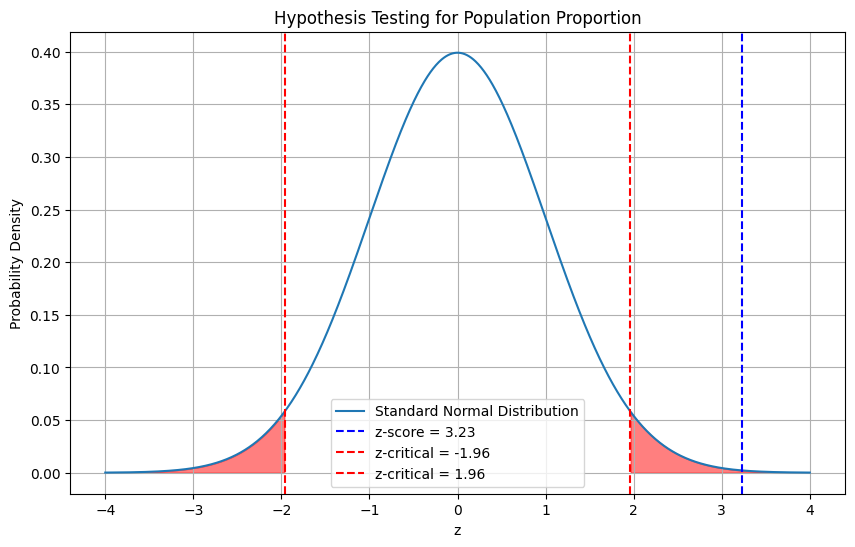

In [3]:
# 13.4 파이썬 실습
# 13.4.2 실제 데이터 세트를 이용한 가설검정
# 실제 데이터를 활용한 모비율의 가설검정
#
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt

# 주어진 데이터
n = 1000  # 표본 크기
p_hat = 450 / n  # 표본 비율
p_0 = 0.4  # 귀무가설 하의 모비율
alpha = 0.05  # 유의수준

# z-값 계산
z_score = (p_hat - p_0) / np.sqrt((p_0 * (1 - p_0)) / n)

# 임계값 계산 (양측검정)
z_critical = norm.ppf(1 - alpha / 2)

# p-값 계산
p_value = 2 * (1 - norm.cdf(abs(z_score)))

# 결과 출력
print(f"Sample Proportion: {p_hat:.2f}")
print(f"z-score: {z_score:.2f}")
print(f"z-critical (for alpha = {alpha}): ±{z_critical:.2f}")
print(f"p-value: {p_value:.4f}")

if abs(z_score) > z_critical:
    print("Reject the null hypothesis (H0).")
else:
    print("Fail to reject the null hypothesis (H0).")

# 시각화
x = np.linspace(-4, 4, 1000)
y = norm.pdf(x)
plt.figure(figsize=(10, 6))
plt.plot(x, y, label='Standard Normal Distribution')
plt.fill_between(x, 0, y, where=(x >= z_critical), color='red', alpha=0.5)
plt.fill_between(x, 0, y, where=(x <= -z_critical), color='red', alpha=0.5)
plt.axvline(z_score, color='blue', linestyle='--', label=f'z-score = {z_score:.2f}')
plt.axvline(-z_critical, color='red', linestyle='--', label=f'z-critical = -{z_critical:.2f}')
plt.axvline(z_critical, color='red', linestyle='--', label=f'z-critical = {z_critical:.2f}')
plt.title('Hypothesis Testing for Population Proportion')
plt.xlabel('z')
plt.ylabel('Probability Density')
plt.legend()
plt.grid(True)
plt.show()